<a href="https://colab.research.google.com/github/Giocrisrai/aprendizaje-refuerzo-duoc/blob/main/notebooks/11_cartpole.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# 11 · El péndulo sobre el carro
**Machine Learning — Duoc UC**

Un carro se mueve a la izquierda o a la derecha. Encima hay un palo que se cae. Cada instante que el palo sigue en pie paga **+1**, hasta un máximo de 500. Si el palo cae, o el carro se sale, el episodio termina.

Al azar el palo dura unos veinte pasos. Con la tabla Q se mantiene mucho más. El juego es CartPole, el ejemplo con el que mucha gente ve por primera vez un agente que «aprende a equilibrar».

El estado no es una casilla. Son cuatro números con decimales:

| Número | Qué mide |
|---|---|
| 0 | posición del carro |
| 1 | velocidad del carro |
| 2 | ángulo del palo |
| 3 | velocidad a la que gira el palo |

Una tabla necesita filas enteras. Dos ángulos distintos no pueden compartir la fila 3,7. Por eso se cortan los cuatro números en tramos. Dos situaciones parecidas caen en la misma caja y comparten la misma fila de Q. Es la agregación de estado del notebook 03, hecha sobre un juego.

La fórmula sigue siendo la del notebook 01. Si el palo se cayó, el futuro vale 0.


In [1]:
#@title ⚙️ Configuración (en Colab instala Gymnasium y deja el juego listo)
import sys, subprocess

def _asegurar(paquete):
    try:
        return __import__(paquete)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])
        return __import__(paquete)

gymnasium = _asegurar("gymnasium")
numpy = _asegurar("numpy")
matplotlib = _asegurar("matplotlib")
print("Listo.", "gymnasium", gymnasium.__version__, "| numpy", numpy.__version__, "| matplotlib", matplotlib.__version__)


Listo. gymnasium 1.4.0 | numpy 2.5.4 | matplotlib 3.11.2


## Cortar el estado en cajas

Cada número se parte en unos pocos bordes. `digitize` dice en qué tramo cayó. La fila de Q es la combinación de los cuatro tramos. No hace falta que los bordes sean perfectos: tienen que separar «palo casi derecho» de «palo ya inclinado».

Al principio ε = 1. La tabla está vacía y el carro se mueve al azar, que es justo la línea base. ε baja hasta 0,01. La curva de entrenamiento mezcla exploración y aciertos. La evaluación de después va en greedy.


In [2]:
import numpy as np
import gymnasium as gym

BORDES = (
    np.linspace(-2.4, 2.4, 6)[1:-1],
    np.linspace(-3.0, 3.0, 6)[1:-1],
    np.linspace(-0.21, 0.21, 8)[1:-1],
    np.linspace(-3.0, 3.0, 8)[1:-1],
)

def caja(observacion):
    return tuple(int(np.digitize(observacion[i], BORDES[i])) for i in range(4))

def entrenar(episodios=4000, alpha=0.1, gamma=0.99, semilla=0):
    entorno = gym.make("CartPole-v1")
    rng = np.random.default_rng(semilla)
    Q = {}
    retornos = np.empty(episodios)

    def fila(estado):
        if estado not in Q:
            Q[estado] = np.zeros(2)
        return Q[estado]

    for episodio in range(episodios):
        epsilon = max(0.01, 1.0 * (1 - episodio / episodios))
        observacion, _ = entorno.reset(seed=semilla + episodio)
        estado = caja(observacion)
        total = 0.0
        for _ in range(500):
            if rng.random() < epsilon:
                accion = int(rng.integers(2))
            else:
                accion = int(np.argmax(fila(estado)))
            observacion, recompensa, termino, truncado, _ = entorno.step(accion)
            siguiente = caja(observacion)
            futuro = 0.0 if termino else gamma * float(fila(siguiente).max())
            fila(estado)[accion] += alpha * (recompensa + futuro - fila(estado)[accion])
            total += recompensa
            estado = siguiente
            if termino or truncado:
                break
        retornos[episodio] = total
    entorno.close()
    return Q, retornos

def jugar(Q, episodios, semilla, aleatorio=False):
    entorno = gym.make("CartPole-v1")
    rng = np.random.default_rng(semilla)
    totales = []
    for k in range(episodios):
        observacion, _ = entorno.reset(seed=semilla + k)
        estado = caja(observacion)
        total = 0.0
        for _ in range(500):
            if aleatorio or estado not in Q:
                accion = int(rng.integers(2))
            else:
                accion = int(np.argmax(Q[estado]))
            observacion, recompensa, termino, truncado, _ = entorno.step(accion)
            estado = caja(observacion)
            total += recompensa
            if termino or truncado:
                break
        totales.append(total)
    entorno.close()
    return np.asarray(totales)

Q, retornos = entrenar()
azar = jugar(Q, 20, semilla=1, aleatorio=True)
greedy = jugar(Q, 20, semilla=90_000)
print("pasos medios al azar: ", round(float(azar.mean()), 1))
print("pasos medios greedy:  ", round(float(greedy.mean()), 1))
print("cajas distintas visitadas:", len(Q))


pasos medios al azar:  21.9
pasos medios greedy:   190.2
cajas distintas visitadas: 415


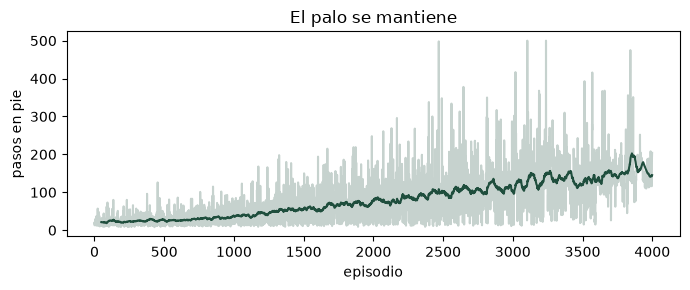

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 3))
plt.plot(retornos, color="#1f4e3d", alpha=0.25)
ventana = np.convolve(retornos, np.ones(50) / 50, mode="valid")
plt.plot(range(49, 49 + len(ventana)), ventana, color="#1f4e3d")
plt.xlabel("episodio")
plt.ylabel("pasos en pie")
plt.title("El palo se mantiene")
plt.tight_layout()
plt.show()


## Por qué esta tabla se acaba

El lago tenía 16 filas. El taxi, 500. Aquí cada caja nueva aparece cuando el carro visita una combinación que no estaba. Con cuatro números ya son cientos de filas, y dos ángulos que cayeron en el mismo tramo se tratan como si fueran el mismo palo.

Si el estado fueran los píxeles de la pantalla, las cajas no alcanzan. Ahí la fila de la tabla se reemplaza por una red: los pesos se pueden buscar, como en el notebook 08, o ajustar con gradiente. Este notebook no entrena esa red. Muestra el momento en que la tabla del notebook 01 deja de ser cómoda.

| Juego | Estado | Qué se repite |
|---|---|---|
| Lago, notebook 09 | 16 casillas | La fórmula y la flecha por casilla |
| Taxi, notebook 10 | 500 combinaciones | La fórmula y el −1 por paso |
| Péndulo, este notebook | 4 números, cortados en cajas | La fórmula, y el límite de la tabla |
| Salmón, notebook 05 | 4 números ya discretos, con ruido | Hay que diseñar el estado antes de llenar Q |

Ninguno de estos tres juegos reemplaza el desafío. Sirven para ver, en Colab, que el ciclo de la grilla sigue siendo el ciclo cuando el dibujo cambia.
